# Archive — MLP Model Section (removed from Notebook 1)

The cells below were removed from `kenya_land_valuation_clean.ipynb` when the project was
split into three notebooks: this was the old in-notebook model section ("Kenya Land
Valuation: MLP Model", Cells M0–M10). They are preserved here exactly as they were,
**including all saved outputs and execution counts** — nothing was re-run.

The printed test metrics from the OLS and MLP evaluation cells are also copied into
`reference_mlp_ols_metrics.md`. The new modelling notebook (Notebook 3) is produced
separately.


<a id="model-section"></a>

# Kenya Land Valuation — MLP Model

This notebook trains a Multi-Layer Perceptron (MLP) to predict `log(price per acre)`
for Kenyan land listings. It reads directly from the final engineered dataset produced
by Part 2 of the pipeline (`kenya_land_engineered_final.parquet`).

**Cell order — run each cell separately, in sequence:**

| Cell | Purpose |
|------|---------|
| M0 — Session setup | Install packages, imports, paths |
| M1 — Load and inspect data | Load parquet, validate target |
| M2 — Feature selection | Define which columns enter the model |
| M3 — Train / val / test split | 70 / 15 / 15 stratified split |
| M4 — Scale features | Fit StandardScaler on train only |
| M5 — OLS baseline | Linear regression reference point |
| M6 — MLP architecture | Define the network class |
| M7 — Training loop | Train with early stopping |
| M8 — Evaluate on test set | Metrics + residual analysis |
| M9 — Visual audit | Prediction charts |
| M10 — Save model | Persist weights and scaler |


<a id="cell-m0"></a>

## Cell M0 — Session Setup

Installs PyTorch (already present on Colab GPU runtimes), mounts Drive, and sets
global plot style and colour constants used throughout the notebook.
Run this every time a new session starts.


In [24]:
from google.colab import drive
drive.mount("/content/drive")

import os, gc, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
warnings.filterwarnings("ignore")

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset+

from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
import joblib

# Project paths — same structure as the pipeline notebooks
PROJECT_ROOT = "/content/drive/MyDrive/kenya_land_valuation"
INTERIM_DATA = f"{PROJECT_ROOT}/data/interim"
MODEL_DIR    = f"{PROJECT_ROOT}/models"
OUTPUTS      = f"{PROJECT_ROOT}/outputs/modelling"

for d in [MODEL_DIR, OUTPUTS]:
    os.makedirs(d, exist_ok=True)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device : {DEVICE}")

# Consistent colour palette
BLUE   = "#2E6DA4"
ORANGE = "#E8A838"
DARK   = "#1B3A5C"
RED    = "#D9534F"

plt.rcParams.update({
    "figure.facecolor" : "white",
    "axes.facecolor"   : "white",
    "axes.spines.top"  : False,
    "axes.spines.right": False,
    "font.family"      : "sans-serif",
    "axes.titlesize"   : 13,
    "axes.labelsize"   : 11,
})

print("Session setup complete.")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Device : cpu
Session setup complete.


<a id="cell-m1"></a>

## Cell M1 — Load and Inspect Data

Loads the final engineered parquet from Phase 8. Drops records where the target
variable is missing, zero, or infinite — these cannot be used for regression.
Prints a summary so you can confirm the dataset shape before proceeding.


In [25]:
DATA_PATH = f"{INTERIM_DATA}/kenya_land_engineered_final.parquet"

df_raw = pd.read_parquet(DATA_PATH)
print(f"Raw records loaded : {len(df_raw):,}")
print(f"Columns            : {list(df_raw.columns)}")

TARGET = "log_price_per_acre"

# Remove records that cannot be used for regression
df_raw = df_raw[df_raw["size_acres"]     > 0].copy()
df_raw = df_raw[df_raw["price_per_acre"] > 0].copy()
df_raw = df_raw[np.isfinite(df_raw[TARGET])].copy()
df_raw = df_raw.reset_index(drop=True)

print(f"\nRecords after cleaning : {len(df_raw):,}")
print(f"Records removed        : {len(pd.read_parquet(DATA_PATH)) - len(df_raw):,}")

print(f"\nTarget variable ({TARGET}):")
print(f"  Min    : {df_raw[TARGET].min():.4f}")
print(f"  Max    : {df_raw[TARGET].max():.4f}")
print(f"  Mean   : {df_raw[TARGET].mean():.4f}")
print(f"  Median : {df_raw[TARGET].median():.4f}")
print(f"  Std    : {df_raw[TARGET].std():.4f}")

Raw records loaded : 1,094
Columns            : ['listing_url', 'listing_no', 'title', 'location', 'prop_type', 'list_date', 'price_ksh', 'price_flag', 'log_price_ksh', 'size_acres', 'size_source', 'log_size_acres', 'latitude', 'longitude', 'geocode_source', 'geocode_confidence', 'county', 'dist_to_nairobi_km', 'dist_to_county_town_km', 'dist_to_water_body_km', 'reference_city', 'reference_city_dist_km', 'amenities_score', 'accessibility_score', 'infrastructure_score', 'infra_source', 'price_per_acre', 'log_price_per_acre']

Records after cleaning : 813
Records removed        : 281

Target variable (log_price_per_acre):
  Min    : 3.5951
  Max    : 20.2133
  Mean   : 16.1720
  Median : 16.9510
  Std    : 2.8765


<a id="cell-m2"></a>

## Cell M2 — Feature Selection

Defines which engineered columns enter the MLP as inputs. All features listed here
were produced by the pipeline: Phases 1-2 (price/size), Phase 3 (geocoding),
Phase 4 (proximity), and Phases 5-7 (pillar scores).

Edit `MLP_FEATURES` here if you want to experiment with different subsets.
The cell also drops any rows that are missing one or more of the required features,
and reports the null count per column before dropping so you can trace gaps back to
the relevant pipeline phase.


In [26]:
MLP_FEATURES = [
    # Size
    "log_size_acres",
    # Proximity
    "dist_to_nairobi_km",
    "dist_to_county_town_km",
    "dist_to_water_body_km",
    "reference_city_dist_km",
    # Geocode quality
    "geocode_confidence",
    # Pillar scores (Phases 5-7)
    "amenities_score",
    "accessibility_score",
    "infrastructure_score",
]

# Check nulls before dropping
required_cols = MLP_FEATURES + [TARGET]
null_counts   = df_raw[required_cols].isnull().sum()
print("Null counts per required column:")
print(null_counts.to_string())

df = df_raw[required_cols].dropna().reset_index(drop=True)

print(f"\nRecords available for modelling : {len(df):,}")
print(f"Records dropped (any null)      : {len(df_raw) - len(df):,}")
print(f"\nFeature count : {len(MLP_FEATURES)}")
print(f"Features      : {MLP_FEATURES}")

Null counts per required column:
log_size_acres              0
dist_to_nairobi_km          0
dist_to_county_town_km      1
dist_to_water_body_km     781
reference_city_dist_km      0
geocode_confidence          0
amenities_score             0
accessibility_score         0
infrastructure_score        0
log_price_per_acre          0

Records available for modelling : 32
Records dropped (any null)      : 781

Feature count : 9
Features      : ['log_size_acres', 'dist_to_nairobi_km', 'dist_to_county_town_km', 'dist_to_water_body_km', 'reference_city_dist_km', 'geocode_confidence', 'amenities_score', 'accessibility_score', 'infrastructure_score']


<a id="cell-m3"></a>

## Cell M3 — Train / Val / Test Split

Splits the data into three non-overlapping sets:

- **Train (70%)** — used to update model weights
- **Validation (15%)** — used for early stopping and hyperparameter decisions
- **Test (15%)** — held out until final evaluation; never seen during training

The random seed is fixed so the split is reproducible across runs.


In [27]:
X = df[MLP_FEATURES].values
y = df[TARGET].values

# First split: hold out 15% as the test set
X_trainval, X_test, y_trainval, y_test = train_test_split(
    X, y, test_size=0.15, random_state=42
)

# Second split: from remaining 85%, hold out ~15% of total as validation
# 0.15 / 0.85 = 0.176
X_train, X_val, y_train, y_val = train_test_split(
    X_trainval, y_trainval, test_size=0.176, random_state=42
)

print(f"Train set  : {len(X_train):,} records  ({len(X_train)/len(X)*100:.1f}%)")
print(f"Val set    : {len(X_val):,}   records  ({len(X_val)/len(X)*100:.1f}%)")
print(f"Test set   : {len(X_test):,}  records  ({len(X_test)/len(X)*100:.1f}%)")
print(f"\nTarget range in each split:")
print(f"  Train : {y_train.min():.3f} to {y_train.max():.3f}")
print(f"  Val   : {y_val.min():.3f} to {y_val.max():.3f}")
print(f"  Test  : {y_test.min():.3f} to {y_test.max():.3f}")

Train set  : 22 records  (68.8%)
Val set    : 5   records  (15.6%)
Test set   : 5  records  (15.6%)

Target range in each split:
  Train : 11.448 to 19.966
  Val   : 6.908 to 19.636
  Test  : 13.528 to 19.966


<a id="cell-m4"></a>

## Cell M4 — Scale Features

MLP training is sensitive to feature magnitude. StandardScaler centres each feature
to zero mean and unit variance using statistics computed on the training set only.
The same fitted scaler is then applied to val and test — never refit on them.
This prevents data leakage from the test set into the scaling step.

The fitted scaler is saved in Cell M10 alongside the model weights so it can be
applied identically at inference time.


In [28]:
scaler = StandardScaler()

X_train_sc = scaler.fit_transform(X_train)   # fit + transform on train
X_val_sc   = scaler.transform(X_val)         # transform only
X_test_sc  = scaler.transform(X_test)        # transform only

print("Feature scaling applied.")
print(f"\nScaler mean (first 5 features)  : {scaler.mean_[:5].round(4)}")
print(f"Scaler scale (first 5 features) : {scaler.scale_[:5].round(4)}")

Feature scaling applied.

Scaler mean (first 5 features)  : [  0.9981 202.2986 202.2986 134.1091  11.8018]
Scaler scale (first 5 features) : [  1.5029 160.0376 160.0376 171.0343  12.0884]


<a id="cell-m5"></a>

## Cell M5 — OLS Baseline

A simple Ordinary Least Squares regression is fitted on the same scaled features
as the MLP. This gives a linear reference point: any R² improvement the MLP achieves
over OLS represents the value of the non-linear architecture. If the MLP does not
clearly beat OLS, the non-linearity is not justified.


In [29]:
ols = LinearRegression()
ols.fit(X_train_sc, y_train)

ols_val_pred  = ols.predict(X_val_sc)
ols_test_pred = ols.predict(X_test_sc)

ols_val_r2    = r2_score(y_val,  ols_val_pred)
ols_test_r2   = r2_score(y_test, ols_test_pred)
ols_test_rmse = np.sqrt(mean_squared_error(y_test, ols_test_pred))
ols_test_mae  = mean_absolute_error(y_test, ols_test_pred)

print("OLS BASELINE")
print(f"  Val  R²   : {ols_val_r2:.4f}")
print(f"  Test R²   : {ols_test_r2:.4f}")
print(f"  Test RMSE : {ols_test_rmse:.4f}")
print(f"  Test MAE  : {ols_test_mae:.4f}")

print("\nOLS Coefficients (feature importance proxy):")
coef_df = pd.Series(ols.coef_, index=MLP_FEATURES).sort_values(key=abs, ascending=False)
print(coef_df.round(4).to_string())

OLS BASELINE
  Val  R²   : 0.3136
  Test R²   : 0.7123
  Test RMSE : 1.3606
  Test MAE  : 1.1784

OLS Coefficients (feature importance proxy):
dist_to_water_body_km     2.3329
reference_city_dist_km   -1.2107
infrastructure_score      0.8221
log_size_acres           -0.8187
dist_to_county_town_km    0.5031
dist_to_nairobi_km        0.5031
geocode_confidence       -0.3331
accessibility_score      -0.2980
amenities_score           0.1590


<a id="cell-m6"></a>

## Cell M6 — MLP Architecture

The network is a four-layer feedforward MLP:

```
Input (n_features)
    -> Linear(128) -> BatchNorm -> ReLU -> Dropout(0.3)
    -> Linear(64)  -> BatchNorm -> ReLU -> Dropout(0.3)
    -> Linear(32)  -> BatchNorm -> ReLU -> Dropout(0.2)
    -> Linear(1)
```

**BatchNorm** normalises activations within each mini-batch, which stabilises training
and allows higher learning rates. **Dropout** randomly zeroes neurons during training,
which acts as regularisation and reduces overfitting. The dropout rate decreases in
deeper layers because the representation is more compressed and harder to recover from
aggressive dropout.


In [30]:
class MLP(nn.Module):
    def __init__(self, input_dim):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, 128),
            nn.BatchNorm1d(128),
            nn.ReLU(),
            nn.Dropout(0.3),

            nn.Linear(128, 64),
            nn.BatchNorm1d(64),
            nn.ReLU(),
            nn.Dropout(0.3),

            nn.Linear(64, 32),
            nn.BatchNorm1d(32),
            nn.ReLU(),
            nn.Dropout(0.2),

            nn.Linear(32, 1)
        )

    def forward(self, x):
        return self.net(x).squeeze(1)


# Instantiate and print parameter count
mlp_model = MLP(input_dim=len(MLP_FEATURES)).to(DEVICE)

total_params    = sum(p.numel() for p in mlp_model.parameters())
trainable_params = sum(p.numel() for p in mlp_model.parameters() if p.requires_grad)

print(f"MLP architecture:")
print(mlp_model)
print(f"\nTotal parameters     : {total_params:,}")
print(f"Trainable parameters : {trainable_params:,}")

MLP architecture:
MLP(
  (net): Sequential(
    (0): Linear(in_features=9, out_features=128, bias=True)
    (1): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): Dropout(p=0.3, inplace=False)
    (4): Linear(in_features=128, out_features=64, bias=True)
    (5): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): ReLU()
    (7): Dropout(p=0.3, inplace=False)
    (8): Linear(in_features=64, out_features=32, bias=True)
    (9): BatchNorm1d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (10): ReLU()
    (11): Dropout(p=0.2, inplace=False)
    (12): Linear(in_features=32, out_features=1, bias=True)
  )
)

Total parameters     : 12,097
Trainable parameters : 12,097


<a id="cell-m7"></a>

## Cell M7 — Training Loop

The training loop uses:

- **Adam optimiser** with L2 weight decay (`weight_decay=1e-4`) as an additional
  regularisation signal on top of dropout
- **ReduceLROnPlateau scheduler** that halves the learning rate when validation loss
  stops improving for 10 consecutive epochs
- **Early stopping** with patience 25 — training stops when validation loss has not
  improved for 25 epochs, and the best weights are restored
- **MSE loss** on the log-transformed target, which is equivalent to minimising the
  squared log-error on the original price scale

The validation loss is computed without dropout (model.eval()) to give a clean
signal for early stopping. Training loss is computed with dropout active.


In [31]:
def make_loader(X, y, batch_size=32, shuffle=True):
    """Wrap numpy arrays in a PyTorch DataLoader."""
    ds = TensorDataset(torch.FloatTensor(X), torch.FloatTensor(y))
    return DataLoader(ds, batch_size=batch_size, shuffle=shuffle)


def train_mlp(model, X_train, y_train, X_val, y_val,
              epochs=300, lr=0.001, patience=25, batch_size=32):
    """
    Train the MLP with early stopping.

    Returns
    -------
    the trained model and the per-epoch loss history.
    """
    train_loader   = make_loader(X_train, y_train, batch_size=batch_size)
    optimizer      = optim.Adam(model.parameters(), lr=lr, weight_decay=1e-4)
    scheduler      = optim.lr_scheduler.ReduceLROnPlateau(
                         optimizer, mode="min", patience=10, factor=0.5)
    criterion      = nn.MSELoss()

    val_tensor     = torch.FloatTensor(X_val).to(DEVICE)
    val_y_np       = y_val

    best_val_loss  = np.inf
    best_weights   = None
    patience_count = 0
    train_losses   = []
    val_losses     = []

    for epoch in range(epochs):
        # Training pass — dropout active
        model.train()
        epoch_loss = 0.0
        for X_batch, y_batch in train_loader:
            X_batch = X_batch.to(DEVICE)
            y_batch = y_batch.to(DEVICE)
            optimizer.zero_grad()
            loss = criterion(model(X_batch), y_batch)
            loss.backward()
            optimizer.step()
            epoch_loss += loss.item()

        # Validation pass — dropout disabled
        model.eval()
        with torch.no_grad():
            val_pred = model(val_tensor).cpu().numpy()
        val_loss = mean_squared_error(val_y_np, val_pred)

        scheduler.step(val_loss)
        train_losses.append(epoch_loss / len(train_loader))
        val_losses.append(val_loss)

        if val_loss < best_val_loss:
            best_val_loss  = val_loss
            best_weights   = {k: v.clone() for k, v in model.state_dict().items()}
            patience_count = 0
        else:
            patience_count += 1
            if patience_count >= patience:
                print(f"  Early stopping at epoch {epoch + 1}")
                print(f"  Best validation MSE : {best_val_loss:.4f}")
                break

    model.load_state_dict(best_weights)
    return model, train_losses, val_losses


print("Starting MLP training...")
mlp_model, train_losses, val_losses = train_mlp(
    mlp_model,
    X_train_sc, y_train,
    X_val_sc,   y_val,
    epochs     = 300,
    lr         = 0.001,
    patience   = 25,
    batch_size = 32,
)

# Quick validation check
mlp_model.eval()
with torch.no_grad():
    mlp_val_pred = mlp_model(torch.FloatTensor(X_val_sc).to(DEVICE)).cpu().numpy()

val_r2   = r2_score(y_val, mlp_val_pred)
val_rmse = np.sqrt(mean_squared_error(y_val, mlp_val_pred))
print(f"\nMLP Validation R²   : {val_r2:.4f}")
print(f"MLP Validation RMSE : {val_rmse:.4f}")



Starting MLP training...

MLP Validation R²   : -1.2299
MLP Validation RMSE : 7.5859


<a id="cell-m8"></a>

## Cell M8 — Evaluate on Test Set

The test set is used exactly once here. All numbers reported from this cell forward
are the final reported performance of the model. Residuals are inspected to check
for systematic bias — a good model should have residuals distributed around zero
with no obvious pattern against predicted values or against individual features.


In [32]:
mlp_model.eval()
with torch.no_grad():
    mlp_test_pred = mlp_model(torch.FloatTensor(X_test_sc).to(DEVICE)).cpu().numpy()

mlp_test_r2   = r2_score(y_test, mlp_test_pred)
mlp_test_rmse = np.sqrt(mean_squared_error(y_test, mlp_test_pred))
mlp_test_mae  = mean_absolute_error(y_test, mlp_test_pred)

print("=" * 55)
print("FINAL TEST SET RESULTS")
print("=" * 55)
header = f"{"Model":<18} {"R2":>8} {"RMSE":>8} {"MAE":>8}"
print(header)
print("-" * 46)
row_ols = f"{"OLS Baseline":<18} {ols_test_r2:>8.4f} {ols_test_rmse:>8.4f} {ols_test_mae:>8.4f}"
row_mlp = f"{"MLP":<18} {mlp_test_r2:>8.4f} {mlp_test_rmse:>8.4f} {mlp_test_mae:>8.4f}"
print(row_ols)
print(row_mlp)

improvement = mlp_test_r2 - ols_test_r2
print(f"\nR² improvement over OLS : {improvement:+.4f}")

# Residual analysis
residuals = y_test - mlp_test_pred
print(f"\nResidual summary:")
print(f"  Mean   : {residuals.mean():.4f}  (close to 0 = unbiased)")
print(f"  Std    : {residuals.std():.4f}")
print(f"  Min    : {residuals.min():.4f}")
print(f"  Max    : {residuals.max():.4f}")
print(f"  |>0.5| : {(np.abs(residuals) > 0.5).sum()} records  (large errors)")

FINAL TEST SET RESULTS
Model                    R2     RMSE      MAE
----------------------------------------------
OLS Baseline         0.7123   1.3606   1.1784
MLP                 -8.6094   7.8633   7.7651

R² improvement over OLS : -9.3217

Residual summary:
  Mean   : 7.7651  (close to 0 = unbiased)
  Std    : 1.2389
  Min    : 5.3659
  Max    : 8.7566
  |>0.5| : 5 records  (large errors)


<a id="cell-m9"></a>

## Cell M9 — Visual Audit

Five charts that together tell the full story of model quality:

1. **Training curves** — confirms the model converged and did not overfit
2. **Predicted vs actual** — points should cluster along the diagonal
3. **Residuals vs predicted** — should show no fan shape or trend (homoscedastic)
4. **Residual distribution** — should be approximately symmetric around zero
5. **OLS vs MLP comparison** — quantifies the benefit of the non-linear architecture


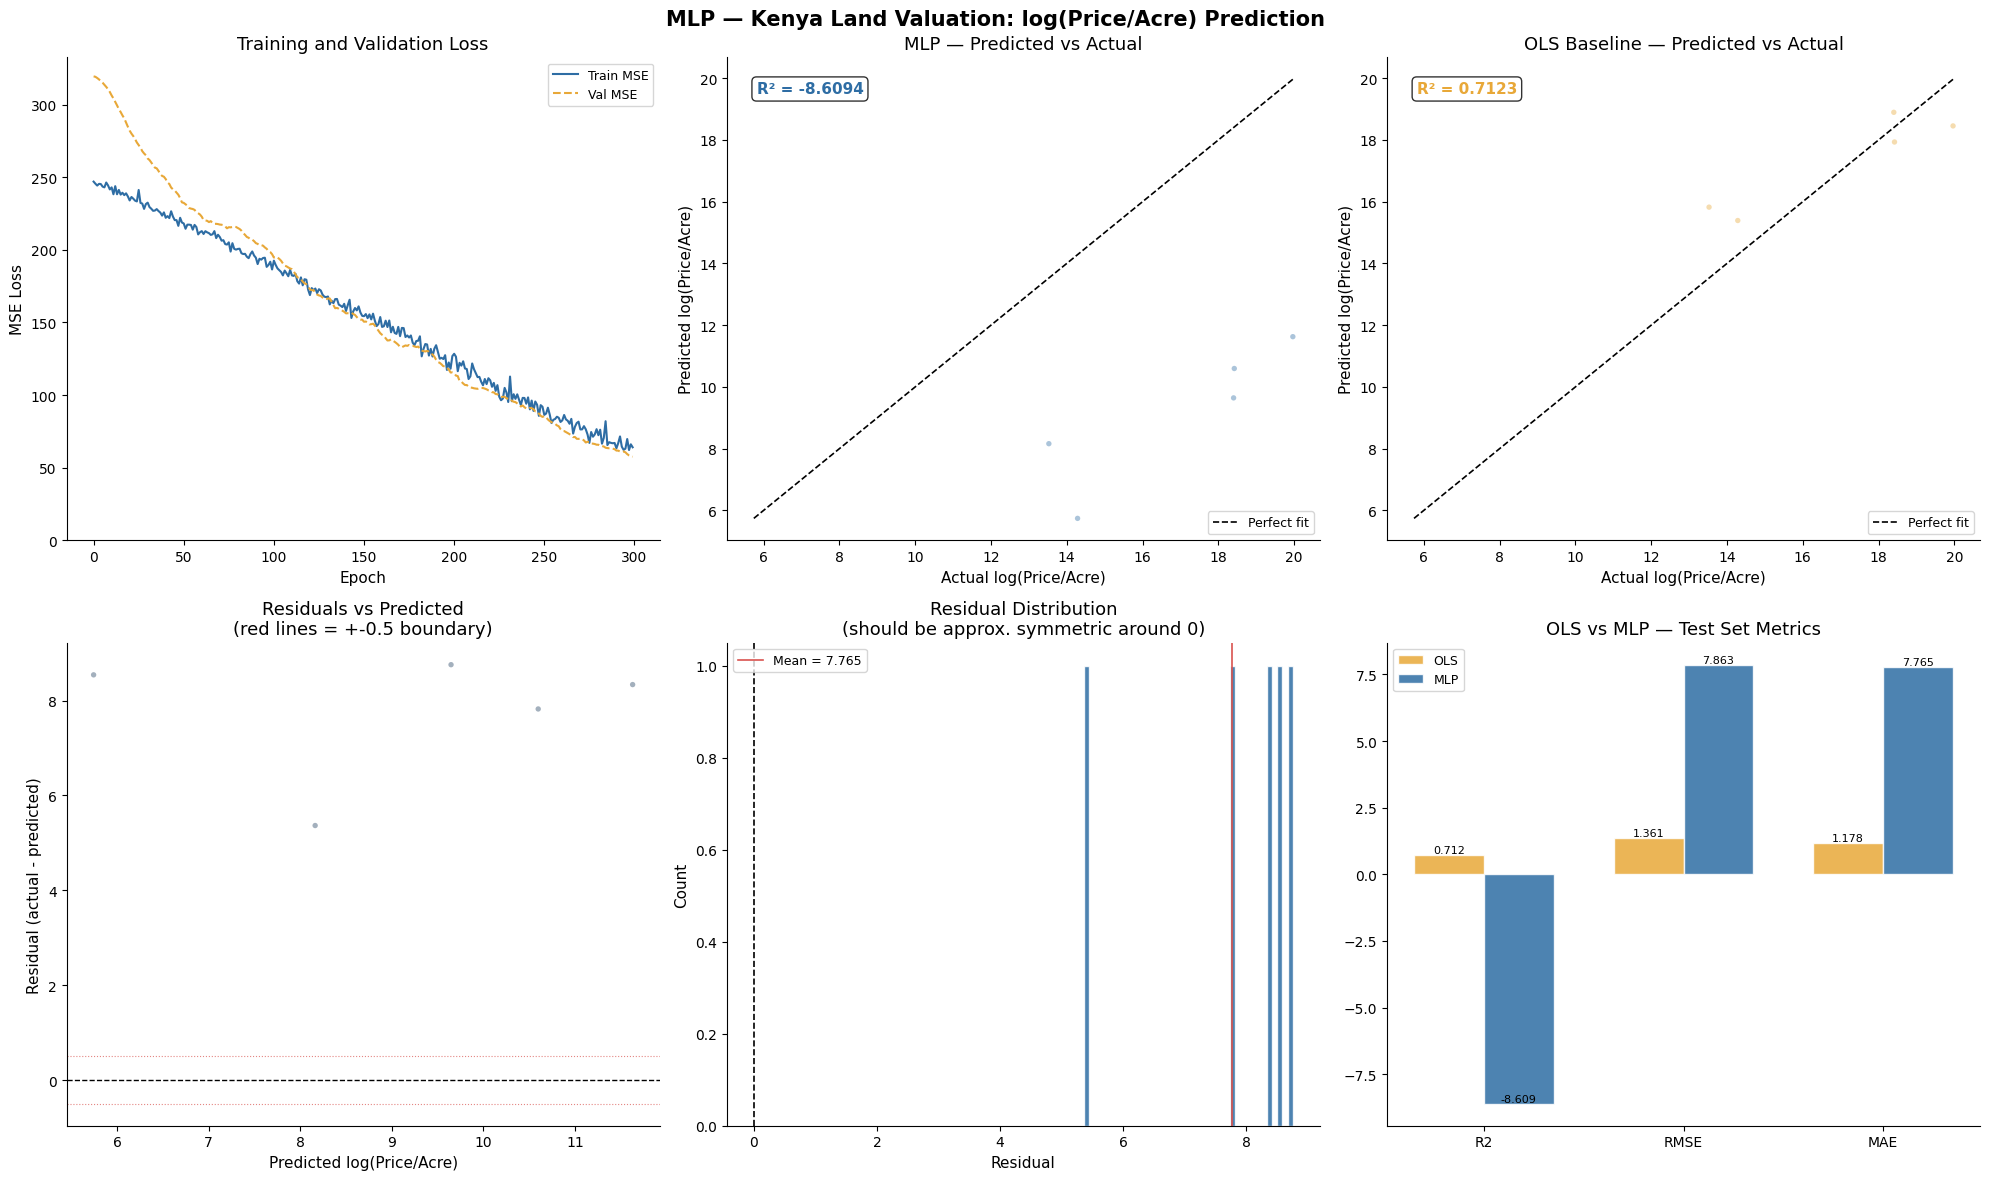

Chart saved to outputs folder.


In [33]:
fig, axes = plt.subplots(2, 3, figsize=(20, 12))
fig.suptitle("MLP — Kenya Land Valuation: log(Price/Acre) Prediction",
             fontsize=15, fontweight="bold")

# 1. Training and validation loss curves
ax = axes[0, 0]
ax.plot(train_losses, color=BLUE, linewidth=1.5, label="Train MSE")
ax.plot(val_losses,   color=ORANGE, linewidth=1.5, linestyle="--", label="Val MSE")
ax.set_title("Training and Validation Loss")
ax.set_xlabel("Epoch")
ax.set_ylabel("MSE Loss")
ax.legend(fontsize=9)
ax.set_ylim(bottom=0)

# 2. Predicted vs actual — MLP
ax = axes[0, 1]
ax.scatter(y_test, mlp_test_pred, alpha=0.4, s=15, color=BLUE, edgecolors="none")
mn = min(y_test.min(), mlp_test_pred.min())
mx = max(y_test.max(), mlp_test_pred.max())
ax.plot([mn, mx], [mn, mx], "k--", linewidth=1.2, label="Perfect fit")
ax.text(0.05, 0.95, f"R² = {mlp_test_r2:.4f}",
        transform=ax.transAxes, fontsize=11, fontweight="bold",
        color=BLUE, va="top",
        bbox=dict(boxstyle="round,pad=0.3", facecolor="white", alpha=0.8))
ax.set_title("MLP — Predicted vs Actual")
ax.set_xlabel("Actual log(Price/Acre)")
ax.set_ylabel("Predicted log(Price/Acre)")
ax.legend(fontsize=9)

# 3. Predicted vs actual — OLS (reference)
ax = axes[0, 2]
ax.scatter(y_test, ols_test_pred, alpha=0.4, s=15, color=ORANGE, edgecolors="none")
ax.plot([mn, mx], [mn, mx], "k--", linewidth=1.2, label="Perfect fit")
ax.text(0.05, 0.95, f"R² = {ols_test_r2:.4f}",
        transform=ax.transAxes, fontsize=11, fontweight="bold",
        color=ORANGE, va="top",
        bbox=dict(boxstyle="round,pad=0.3", facecolor="white", alpha=0.8))
ax.set_title("OLS Baseline — Predicted vs Actual")
ax.set_xlabel("Actual log(Price/Acre)")
ax.set_ylabel("Predicted log(Price/Acre)")
ax.legend(fontsize=9)

# 4. Residuals vs predicted (homoscedasticity check)
ax = axes[1, 0]
ax.scatter(mlp_test_pred, residuals, alpha=0.4, s=15, color=DARK, edgecolors="none")
ax.axhline(0, color="black", linewidth=1.0, linestyle="--")
ax.axhline( 0.5, color=RED, linewidth=0.8, linestyle=":", alpha=0.7)
ax.axhline(-0.5, color=RED, linewidth=0.8, linestyle=":", alpha=0.7)
ax.set_title("Residuals vs Predicted\n(red lines = +-0.5 boundary)")
ax.set_xlabel("Predicted log(Price/Acre)")
ax.set_ylabel("Residual (actual - predicted)")

# 5. Residual distribution
ax = axes[1, 1]
ax.hist(residuals, bins=40, color=BLUE, edgecolor="white", alpha=0.85)
ax.axvline(0, color="black", linewidth=1.2, linestyle="--")
ax.axvline(residuals.mean(), color=RED, linewidth=1.2, linestyle="-",
           label=f"Mean = {residuals.mean():.3f}")
ax.set_title("Residual Distribution\n(should be approx. symmetric around 0)")
ax.set_xlabel("Residual")
ax.set_ylabel("Count")
ax.legend(fontsize=9)

# 6. OLS vs MLP metric comparison
ax = axes[1, 2]
metrics     = ["R2", "RMSE", "MAE"]
ols_vals    = [ols_test_r2,   ols_test_rmse, ols_test_mae]
mlp_vals    = [mlp_test_r2,   mlp_test_rmse, mlp_test_mae]
x           = np.arange(len(metrics))
width       = 0.35
bars_ols    = ax.bar(x - width/2, ols_vals, width, label="OLS",
                     color=ORANGE, edgecolor="white", alpha=0.85)
bars_mlp    = ax.bar(x + width/2, mlp_vals, width, label="MLP",
                     color=BLUE,   edgecolor="white", alpha=0.85)
ax.set_title("OLS vs MLP — Test Set Metrics")
ax.set_xticks(x)
ax.set_xticklabels(metrics)
ax.legend(fontsize=9)
for bar in list(bars_ols) + list(bars_mlp):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.005,
            f"{bar.get_height():.3f}", ha="center", va="bottom", fontsize=8)

plt.tight_layout()
plt.savefig(f"{OUTPUTS}/mlp_evaluation.png", dpi=150, bbox_inches="tight")
plt.show()
print("Chart saved to outputs folder.")

<a id="cell-m10"></a>

## Cell M10 — Save Model

Saves four artefacts needed to reproduce predictions on new data:

- `mlp_model.pt` — the PyTorch model weights (state dict)
- `mlp_scaler.pkl` — the fitted StandardScaler (must be applied before inference)
- `mlp_feature_list.pkl` — the ordered list of feature names (ensures column alignment)
- `mlp_results.csv` — the test set metric summary for reporting

To load and use the model later:
```python
scaler    = joblib.load("mlp_scaler.pkl")
features  = joblib.load("mlp_feature_list.pkl")
model     = MLP(input_dim=len(features))
model.load_state_dict(torch.load("mlp_model.pt"))
model.eval()
```


In [35]:
import joblib, numpy as np
import sklearn
print(f"numpy: {np.__version__}, sklearn: {sklearn.__version__}")
joblib.dump(scaler,        f"{MODEL_DIR}/mlp_scaler.pkl",        compress=0)
joblib.dump(MLP_FEATURES,  f"{MODEL_DIR}/mlp_feature_list.pkl",  compress=0)
joblib.dump([128, 64, 32], f"{MODEL_DIR}/mlp_hidden_layers.pkl", compress=0)
torch.save(mlp_model.state_dict(), f"{MODEL_DIR}/mlp_model.pt")

# Save results summary
results_df = pd.DataFrame({
    "model"     : ["OLS Baseline", "MLP"],
    "R2"        : [ols_test_r2,   mlp_test_r2],
    "RMSE"      : [ols_test_rmse, mlp_test_rmse],
    "MAE"       : [ols_test_mae,  mlp_test_mae],
})
results_df.to_csv(f"{OUTPUTS}/mlp_results.csv", index=False)
print(f"Saved: mlp_results.csv")

print("\n" + "=" * 55)
print("FINAL SUMMARY")
print("=" * 55)
print(f"Model         : MLP  ({sum(p.numel() for p in mlp_model.parameters()):,} parameters)")
print(f"Features      : {len(MLP_FEATURES)}")
print(f"Train records : {len(X_train):,}")
print(f"Test R²       : {mlp_test_r2:.4f}")
print(f"Test RMSE     : {mlp_test_rmse:.4f}")
print(f"Test MAE      : {mlp_test_mae:.4f}")
print(f"OLS R² (ref)  : {ols_test_r2:.4f}")
print(f"R² gain       : {mlp_test_r2 - ols_test_r2:+.4f}")
print(f"\nAll artefacts saved to: {MODEL_DIR}")

numpy: 2.0.2, sklearn: 1.6.1
Saved: mlp_results.csv

FINAL SUMMARY
Model         : MLP  (12,097 parameters)
Features      : 9
Train records : 22
Test R²       : -8.6094
Test RMSE     : 7.8633
Test MAE      : 7.7651
OLS R² (ref)  : 0.7123
R² gain       : -9.3217

All artefacts saved to: /content/drive/MyDrive/kenya_land_valuation/models
